# CodeAlpha Task 4: Disease Prediction

Run the cells from top to bottom (Shift + Enter runs one cell).

**In Google Colab:** run the install cell first. Charts are saved to `images/` and also shown below each cell.

In [1]:
# Install the libraries (Colab already has most; this is quick)
%pip install -q scikit-learn xgboost seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1. Import the tools (libraries) we need
A "library" is code someone else wrote that we can reuse.
- numpy / pandas: work with numbers and tables
- matplotlib / seaborn: draw charts
- scikit-learn (sklearn): the main machine learning toolbox
- xgboost: a strong model type called "gradient boosted trees"
- joblib: saves a trained model to a file

In [2]:
from pathlib import Path

import joblib
import matplotlib

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Folders where outputs go. Path(__file__) is this file; .parent.parent is the project folder.
try:
    ROOT = Path(__file__).resolve().parent.parent
except NameError:  # inside a notebook there is no __file__, so use the folder above notebooks/
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES = ROOT / "images"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for folder in (IMAGES, RESULTS, MODELS):
    folder.mkdir(exist_ok=True)

# A "random seed" makes anything random (like shuffling) happen the same way every run,
# so you and anyone checking your work get the same numbers.
SEED = 42

## 2. Load the data
The dataset is the UCI Breast Cancer Wisconsin (Diagnostic) dataset.
It ships inside scikit-learn, so there is nothing to download.
569 patients (rows), 30 measurements each (columns).

In [3]:
data = load_breast_cancer(as_frame=True)
X = data.data  # the 30 feature columns, as a pandas table (a "DataFrame")

# In this dataset, target 0 means malignant and 1 means benign.
# We flip it so that 1 = malignant, because the cancer case is the one we care
# about catching. "Positive" in the scores below will then mean "malignant".
y = 1 - data.target
y.name = "malignant"

print("Rows (patients), columns (features):", X.shape)
print("Malignant (1) vs benign (0) counts:")
print(y.value_counts())
print("\nFirst 5 rows:")
print(X.head())

Rows (patients), columns (features): (569, 30)
Malignant (1) vs benign (0) counts:
malignant
0    357
1    212
Name: count, dtype: int64

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13

## 3. Explore the data (EDA = Exploratory Data Analysis)
Before training, look at the data. Two charts:
1. How many of each class we have (class balance).
2. Which features move together (correlation). Values near +1 or -1 mean two
   features carry nearly the same information.

Missing values in the whole table: 0
                              mean         std        min         max
mean radius              14.127292    3.524049    6.98100    28.11000
mean texture             19.289649    4.301036    9.71000    39.28000
mean perimeter           91.969033   24.298981   43.79000   188.50000
mean area               654.889104  351.914129  143.50000  2501.00000
mean smoothness           0.096360    0.014064    0.05263     0.16340
mean compactness          0.104341    0.052813    0.01938     0.34540
mean concavity            0.088799    0.079720    0.00000     0.42680
mean concave points       0.048919    0.038803    0.00000     0.20120
mean symmetry             0.181162    0.027414    0.10600     0.30400
mean fractal dimension    0.062798    0.007060    0.04996     0.09744


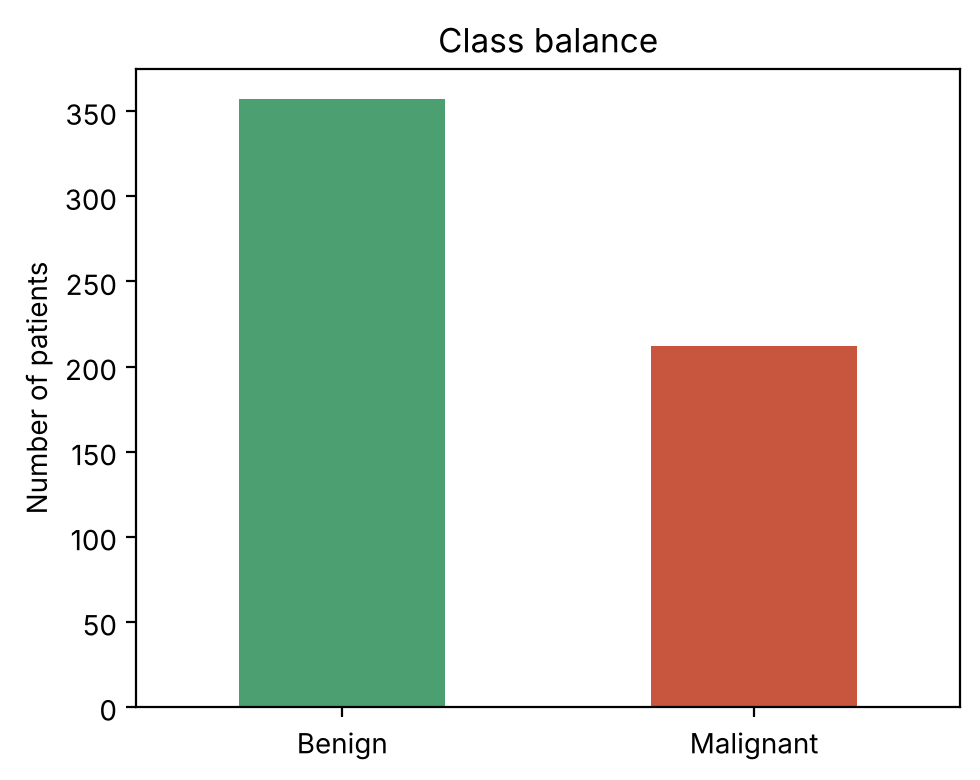

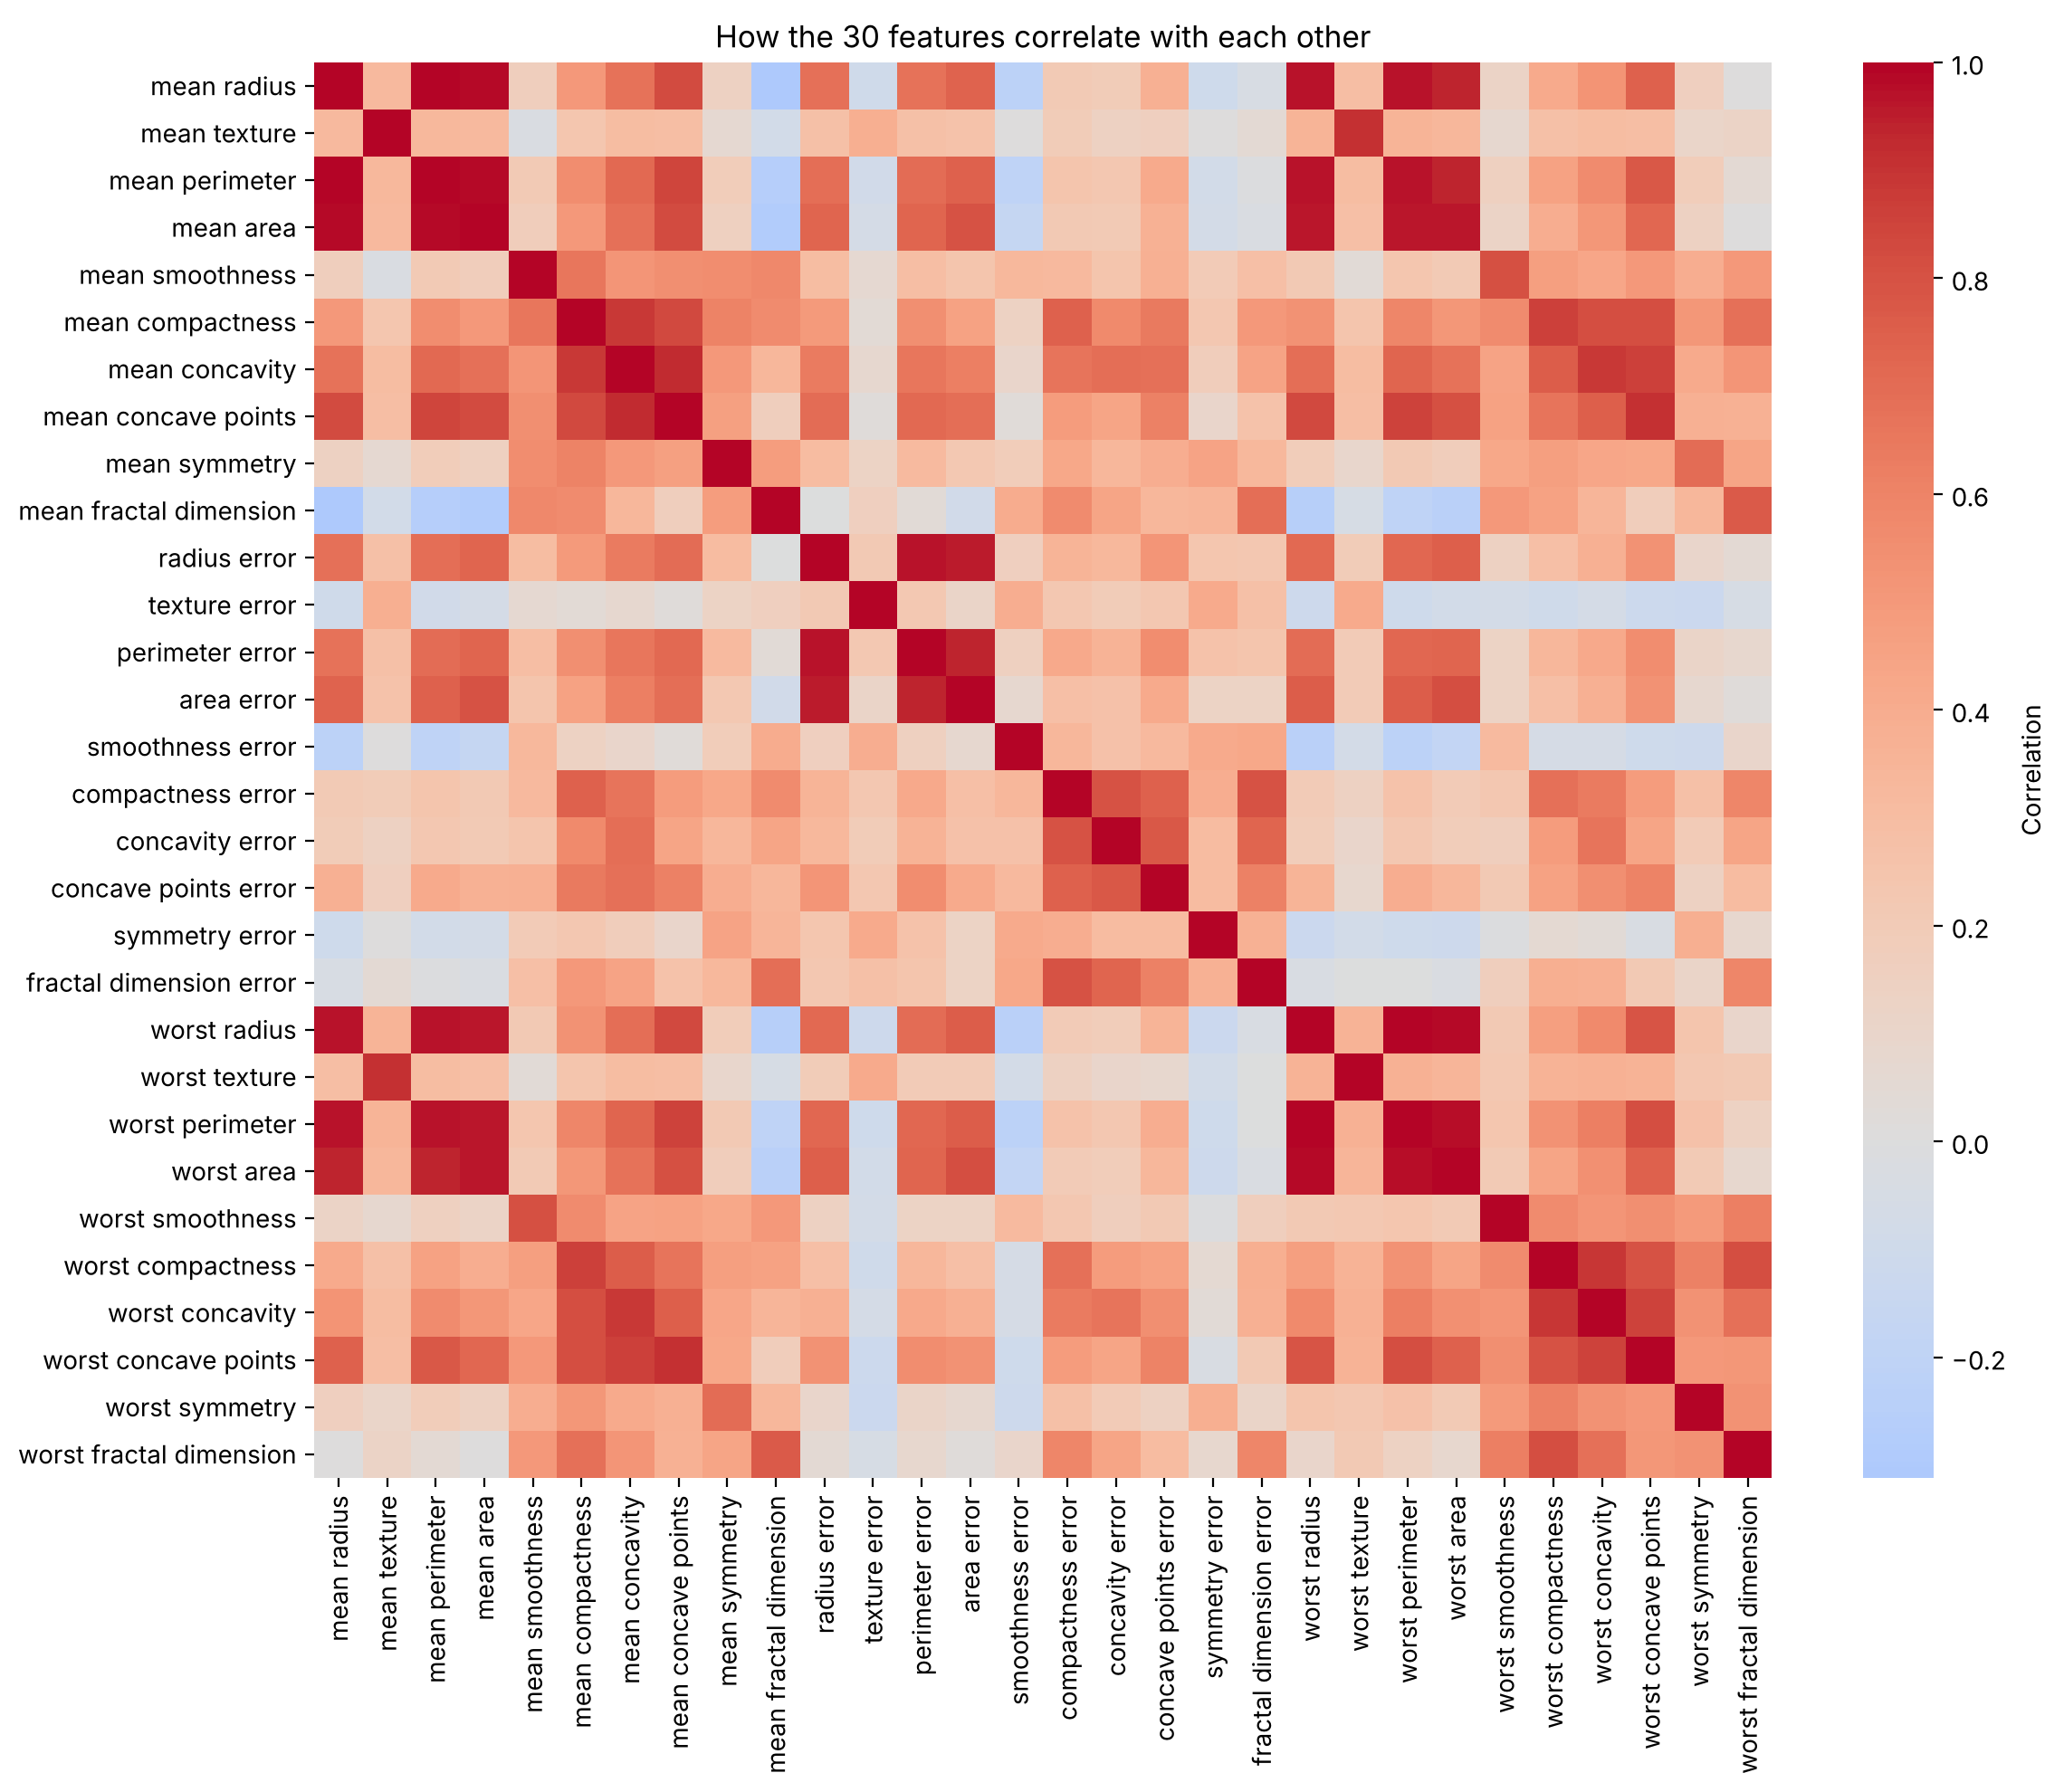

In [4]:
print("Missing values in the whole table:", int(X.isna().sum().sum()))
print(X.describe().T[["mean", "std", "min", "max"]].head(10))

fig, ax = plt.subplots(figsize=(5, 4))
y.map({0: "Benign", 1: "Malignant"}).value_counts().plot(kind="bar", ax=ax, color=["#4C9F70", "#C8553D"])
ax.set_title("Class balance")
ax.set_ylabel("Number of patients")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMAGES / "class_balance.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "Correlation"})
ax.set_title("How the 30 features correlate with each other")
plt.tight_layout()
plt.savefig(IMAGES / "correlation_heatmap.png", dpi=150)
plt.show()

## 4. Split into training and test sets
We hide 20% of patients as a test set. The models never see them while learning.
stratify=y keeps the same malignant/benign ratio in both parts.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Training patients:", len(X_train), "| Test patients:", len(X_test))

Training patients: 455 | Test patients: 114


## 5. Build the four models
A Pipeline chains steps. For Logistic Regression and SVM we first SCALE the
features (so a column measured in thousands doesn't drown out one measured in
fractions), then fit the model. Tree models (Random Forest, XGBoost) don't
need scaling, because they only ask "is this value above or below a cutoff?".

- Logistic Regression: draws a straight boundary between the two classes.
- SVM (Support Vector Machine): finds the boundary with the widest safety gap.
- Random Forest: hundreds of decision trees vote; the majority wins.
- XGBoost: trees built one after another, each fixing the last one's mistakes.

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=SEED)),
    ]),
    "SVM": Pipeline([
        ("scale", StandardScaler()),
        # An SVM gives a yes/no answer but not a probability. CalibratedClassifierCV
        # wraps it so it can also say "83% chance malignant", which ROC curves need.
        ("model", CalibratedClassifierCV(SVC(random_state=SEED), ensemble=False)),
    ]),
    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(n_estimators=300, random_state=SEED)),
    ]),
    "XGBoost": Pipeline([
        ("model", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                eval_metric="logloss", random_state=SEED)),
    ]),
}

## 6. Cross-validation on the training set only
Cross-validation (CV) splits the training data into 5 parts, trains on 4,
checks on the 5th, and rotates 5 times. The average is a fairer score than a
single split, and we still haven't touched the test set.
ROC-AUC: 1.0 is perfect ranking of sick vs healthy, 0.5 is a coin flip.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:20s} CV ROC-AUC = {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression  CV ROC-AUC = 0.9958 (+/- 0.0047)
SVM                  CV ROC-AUC = 0.9949 (+/- 0.0050)


Random Forest        CV ROC-AUC = 0.9880 (+/- 0.0073)


XGBoost              CV ROC-AUC = 0.9936 (+/- 0.0044)


## 7. Tune the settings (hyperparameters) of two models
Hyperparameters are knobs we choose before training, like how strict the
model is. GridSearchCV tries every combination in a small grid with CV and
keeps the best. We tune Logistic Regression (knob C) and SVM (C and gamma).

In [8]:
grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10, 100]},
    # "model__estimator__C" means: inside the step named "model", the wrapped SVM's C knob.
    "SVM": {"model__estimator__C": [0.1, 1, 10, 100], "model__estimator__gamma": ["scale", 0.01, 0.001]},
}
for name, grid in grids.items():
    search = GridSearchCV(models[name], grid, cv=cv, scoring="roc_auc")
    search.fit(X_train, y_train)
    print(f"{name}: best settings {search.best_params_}, CV ROC-AUC {search.best_score_:.4f}")
    models[name] = search.best_estimator_  # keep the tuned version

Logistic Regression: best settings {'model__C': 1}, CV ROC-AUC 0.9958


SVM: best settings {'model__estimator__C': 100, 'model__estimator__gamma': 0.001}, CV ROC-AUC 0.9960


## 8. Final test: train on all training data, score on the hidden test set
Metrics (with "positive" = malignant):
- Accuracy: share of all predictions that are right.
- Precision: of patients we flagged malignant, the share that truly were.
- Recall: of truly malignant patients, the share we caught. Most important here,
  because missing a cancer is the worst mistake.
- F1: one number balancing precision and recall.
- ROC-AUC: how well the model ranks malignant above benign.

In [9]:
rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)  # 0 or 1 for each test patient
    prob = pipe.predict_proba(X_test)[:, 1]  # probability of malignant
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).sort_values(["recall", "roc_auc"], ascending=False).round(4)
results.to_csv(RESULTS / "results.csv", index=False)
print(results.to_string(index=False))

# The "best" model: highest recall (fewest missed cancers), ties broken by ROC-AUC.
best_name = results.iloc[0]["model"]
best_model = models[best_name]
print("\nBest model:", best_name)
print(classification_report(y_test, best_model.predict(X_test), target_names=["Benign", "Malignant"]))

              model  accuracy  precision  recall     f1  roc_auc
Logistic Regression    0.9649      0.975  0.9286 0.9512   0.9960
                SVM    0.9737      1.000  0.9286 0.9630   0.9957
      Random Forest    0.9737      1.000  0.9286 0.9630   0.9944
            XGBoost    0.9649      1.000  0.9048 0.9500   0.9937

Best model: Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 9. Charts for the results
- Confusion matrix: rows are the truth, columns the prediction. The off-diagonal
  boxes are mistakes. The bottom-left box (malignant predicted as benign) is the
  dangerous one.
- ROC curves: all four models on one chart. Closer to the top-left is better.

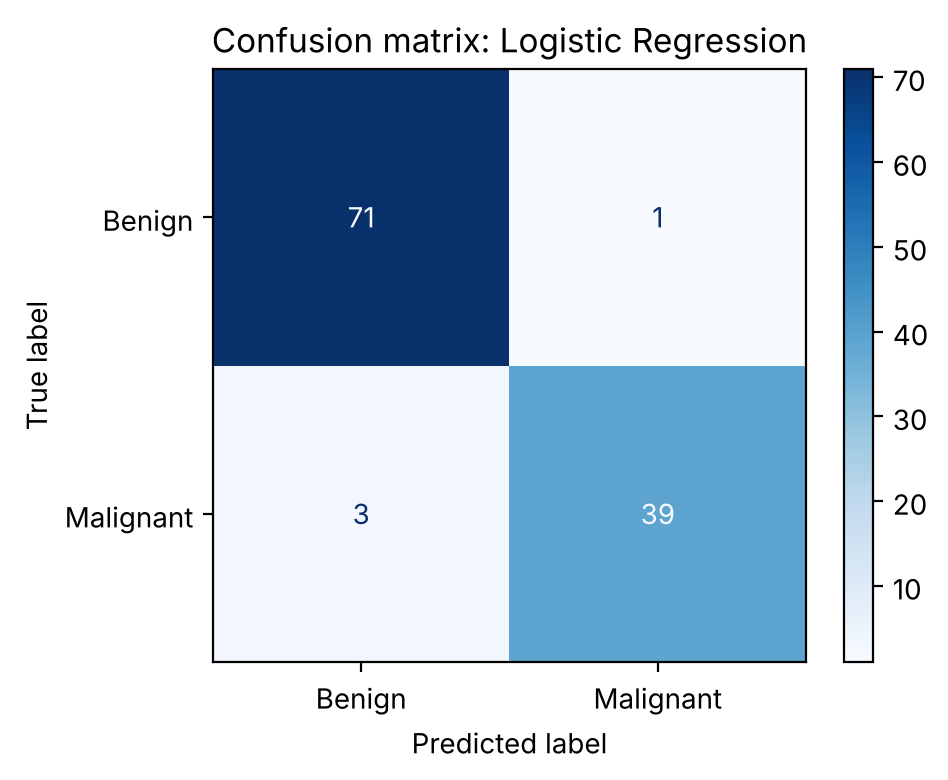

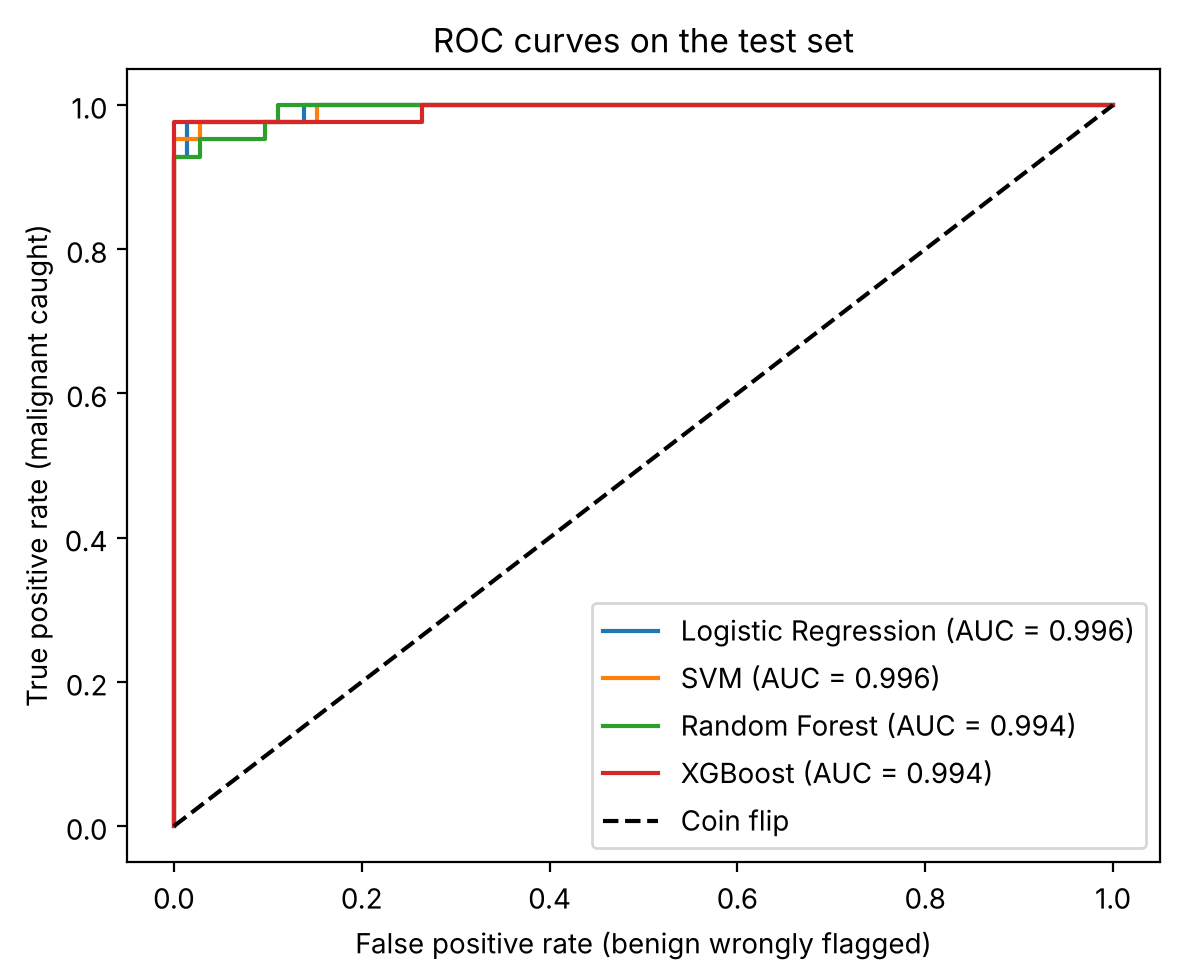

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test,
                                      display_labels=["Benign", "Malignant"], cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.savefig(IMAGES / "confusion_matrix.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in models.items():
    prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)  # false/true positive rate at every threshold
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Coin flip")
ax.set_xlabel("False positive rate (benign wrongly flagged)")
ax.set_ylabel("True positive rate (malignant caught)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMAGES / "roc_curves.png", dpi=150)
plt.show()

## 10. Which features matter most?
A Random Forest can report how much each feature helped its decisions
("feature importance"). This helps explain the model in your video.

Top 10 features:
 worst perimeter         0.1431
worst area              0.1424
worst concave points    0.1130
mean concave points     0.0887
worst radius            0.0826
mean radius             0.0610
mean perimeter          0.0529
mean area               0.0438
mean concavity          0.0398
area error              0.0322
dtype: float64


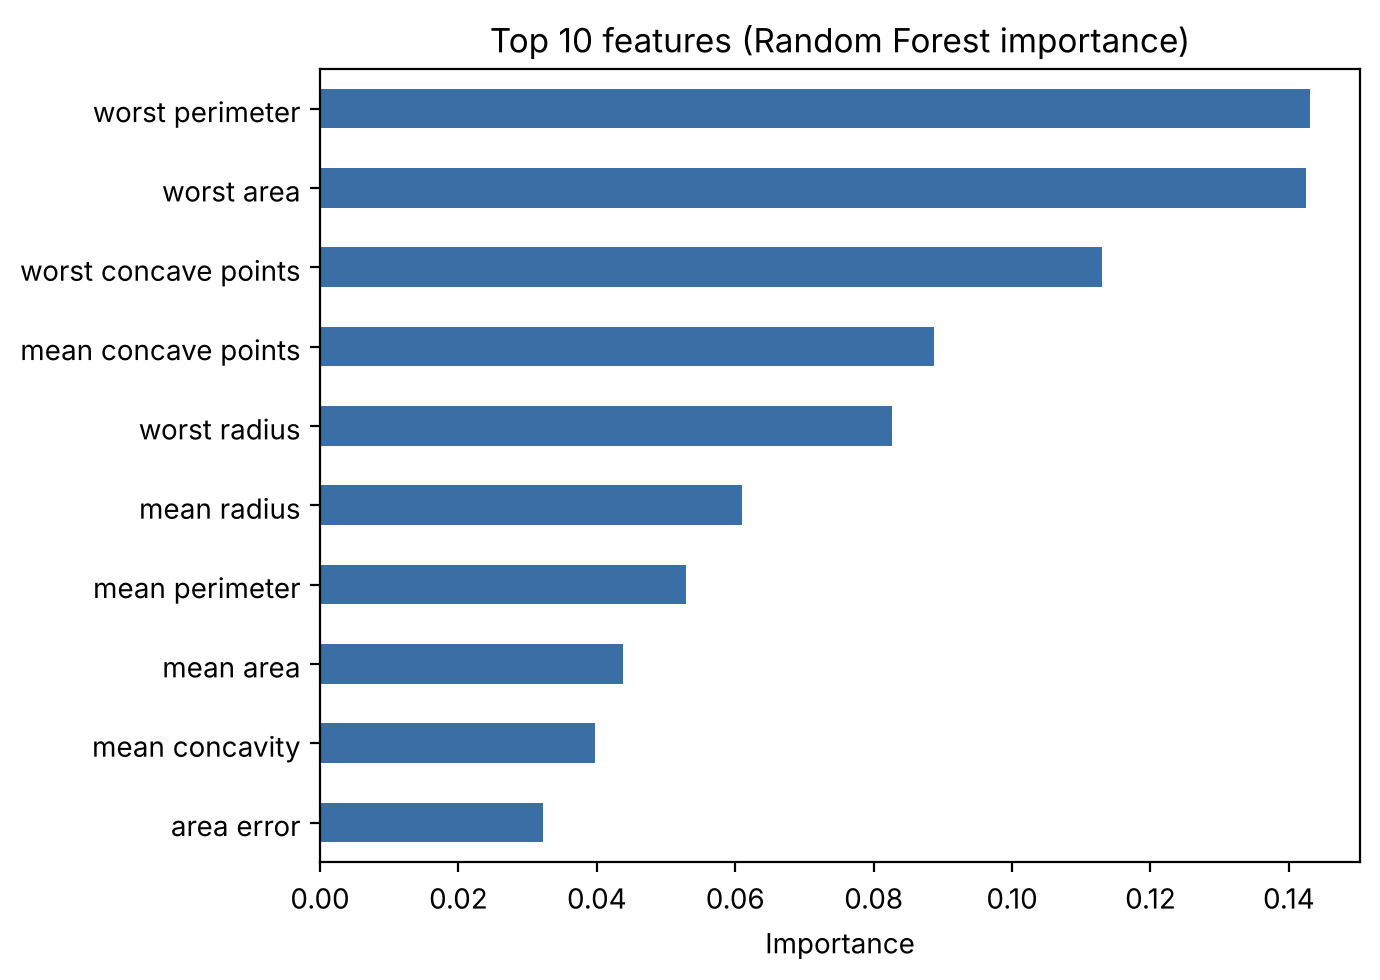

In [11]:
rf = models["Random Forest"].named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print("Top 10 features:\n", importance.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
importance.sort_values().plot(kind="barh", ax=ax, color="#3A6EA5")
ax.set_title("Top 10 features (Random Forest importance)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(IMAGES / "feature_importance.png", dpi=150)
plt.show()

## 11. Save the best model
joblib writes the trained model to a file, so predict.py can use it later
without training again. We also save the column names it expects.

In [12]:
joblib.dump({"model": best_model, "name": best_name, "features": list(X.columns)},
            MODELS / "best_model.joblib")
print("Saved", MODELS / "best_model.joblib")

Saved /tmp/claude-0/-home-user/8427e045-86eb-5afb-a02b-56aa01a202ac/scratchpad/build/CodeAlpha_DiseasePrediction/models/best_model.joblib
